# Taller de Aprendizaje No Supervisado
## Parte 1: Dataset de Setas (variables categóricas)

### Mushroom Dataset

Podéis obtener el conjunto de datos en el siguiente enlace:

[Mushroom Dataset](https://www.kaggle.com/uciml/mushroom-classification)

Como podréis comprobar, hay **muchas variables, todas categóricas**, por lo que las exploraciones con *scatterplot* no nos serán útiles como en otros casos.

La variable a predecir es `class` (`e` = comestible / *edible*, `p` = venenosa / *poisonous*) y es **binaria**.

> En este taller usaremos las etiquetas **solo para validar** lo que descubre el clustering. La idea del aprendizaje no supervisado es encontrar estructura *sin* mirar la etiqueta.

### Algoritmos que cubriremos

**Reducción de dimensionalidad:** PCA (lineal) y t-SNE (no lineal).

**Clustering:** K-Means, Clustering Jerárquico (Aglomerativo), Gaussian Mixture Models (GMM) y DBSCAN.

**Evaluación:** método del codo, *silhouette*, Davies-Bouldin, Calinski-Harabasz y (como tenemos etiqueta) Adjusted Rand Index y NMI.

**Detección de anomalías:** Isolation Forest.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook, justo debajo de la celda que los crea.
import warnings
warnings.filterwarnings("ignore")  # oculta avisos (FutureWarning, etc.) para que la salida quede limpia en clase

# Tablas y cálculo numérico
import pandas as pd      # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np       # arrays y operaciones matemáticas rápidas
# Gráficos
import seaborn as sns            # gráficos estadísticos bonitos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos (títulos, ejes, plt.show())
# Preparación de datos y reducción de dimensiones
from sklearn.model_selection import train_test_split  # separa datos en entrenamiento y examen
from sklearn.decomposition import PCA                 # reducción de dimensiones lineal
# Algoritmos de clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.manifold import TSNE                     # reducción de dimensiones no lineal (solo para visualizar)
from sklearn.mixture import GaussianMixture          # GMM: clusters como "nubes" probabilísticas
# Modelos supervisado y de anomalías
from sklearn.ensemble import RandomForestClassifier, IsolationForest
# Métricas para evaluar los clusters (3 internas + 2 que usan la etiqueta: ARI y NMI)
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
# Para dibujar el dendrograma
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid')  # estilo visual de todos los gráficos: fondo blanco con rejilla
RANDOM_STATE = 42 

### Leer conjunto de datos y primer vistazo

In [2]:
df = pd.read_csv('data/mushrooms.csv')
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### Exploración de datos

In [3]:
df.describe().T   # al ser categóricas: count, unique, top y freq

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

class
e    4208
p    3916
Name: count, dtype: int64

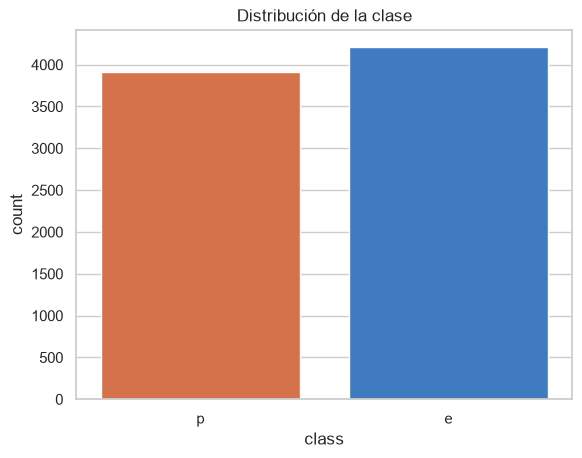

Filas duplicadas: 0


In [5]:
# Balance de la variable objetivo (solo como contexto)
PALETA = {'e': '#2a78d6', 'p': '#eb6834'}
display(df['class'].value_counts())
sns.countplot(data=df, x='class', hue='class', palette=PALETA)
plt.title('Distribución de la clase')
plt.show()
print('Filas duplicadas:', df.duplicated().sum())

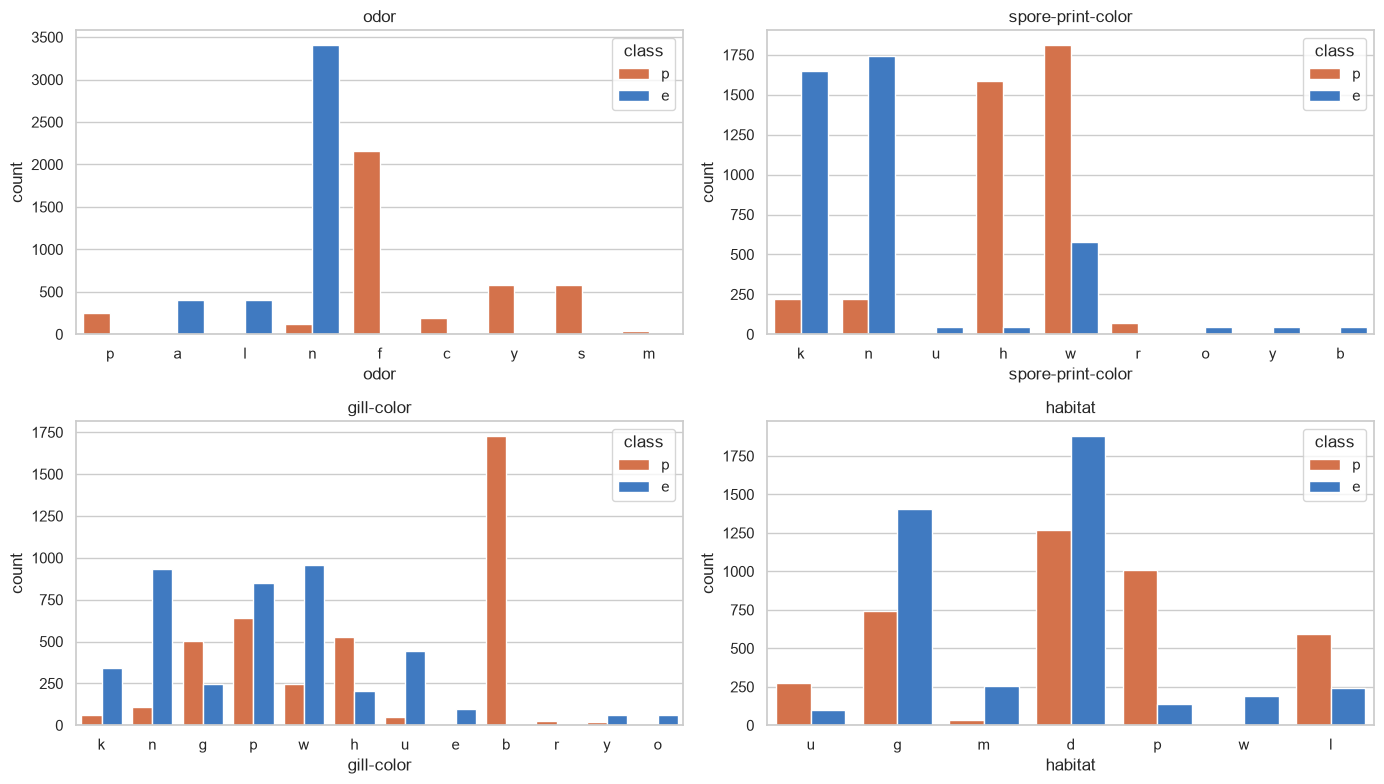

In [6]:
# EDA: ¿cómo se reparte la clase según algunas variables?
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), ['odor', 'spore-print-color', 'gill-color', 'habitat']):
    sns.countplot(data=df, x=col, hue='class', palette=PALETA, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Las clases están bastante equilibradas (4208 comestibles y 3916 venenosas). `odor` destaca: en la mayoría de sus categorías aparece una sola clase, así que es una variable muy informativa.

#### Calcular el número de nulos de cada feature

In [7]:
df.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

#### Buscar valores extraños. Para ello, ver los valores únicos en cada feature

In [8]:
n_values = df.nunique().reset_index()
n_values.columns = ['feature', 'n_values']
display(n_values.sort_values('n_values'))

# Buscar el nulo encubierto '?'
interrogantes = (df == '?').sum()
interrogantes[interrogantes > 0]

,feature,n_values
16,veil-type,1
0,class,2
6,gill-attachment,2
7,gill-spacing,2
10,stalk-shape,2
8,gill-size,2
4,bruises,2
18,ring-number,3
12,stalk-surface-above-ring,4
17,veil-color,4


stalk-root    2480
dtype: int64

Observad dos cosas:
- `veil-type` tiene **un único valor** → no aporta información.
- `stalk-root` contiene el valor `'?'`, que en realidad es un **valor desconocido (nulo encubierto)**.

#### Tratar aquellos valores que entendamos que sean nulos

In [9]:
moda = df.loc[df['stalk-root'] != '?', 'stalk-root'].mode()[0]
n_imputados = (df['stalk-root'] == '?').sum()
df['stalk-root'] = df['stalk-root'].replace('?', moda)

print(f"Imputados {n_imputados} valores ({n_imputados / len(df):.1%}) con la moda '{moda}'")
df['stalk-root'].value_counts()

Imputados 2480 valores (30.5%) con la moda 'b'


stalk-root
b    6256
e    1120
c     556
r     192
Name: count, dtype: int64

**Limitación:** `?` afecta a cerca del 30 % de las filas, así que imputar con la moda infla mucho esa categoría. Una alternativa razonable es dejar `?` como categoría propia.

#### ¿Todas las features aportan información? Si alguna no aporta, eliminadla

In [10]:
constantes = [c for c in df.columns if df[c].nunique() == 1]
df = df.drop(columns=constantes)
print('Eliminadas:', constantes, '| Dimensiones:', df.shape)

Eliminadas: ['veil-type'] | Dimensiones: (8124, 22)


#### Separar entre variables predictoras y variable a predecir

In [11]:
y = df['class']
X = df.drop(columns='class')
y_bin = (y == 'p').astype(int)   # 1 = venenosa (solo para validar)
X.shape, y.shape

((8124, 21), (8124,))

#### Codificar correctamente las variables categóricas a numéricas

In [12]:
X = pd.get_dummies(X, dtype=int)
print(X.shape)
X.head()

(8124, 115)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


#### Train / test split

In [13]:
# Os lo dejamos a todos igual
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

## PCA

Es un conjunto de datos del que aún no hemos visto gráficas, así que vamos a hacer algunas. Tenemos muchas variables, **PCA al rescate**: le pedimos dos dimensiones y las pintamos. Serán **las que retengan más información (varianza)**.

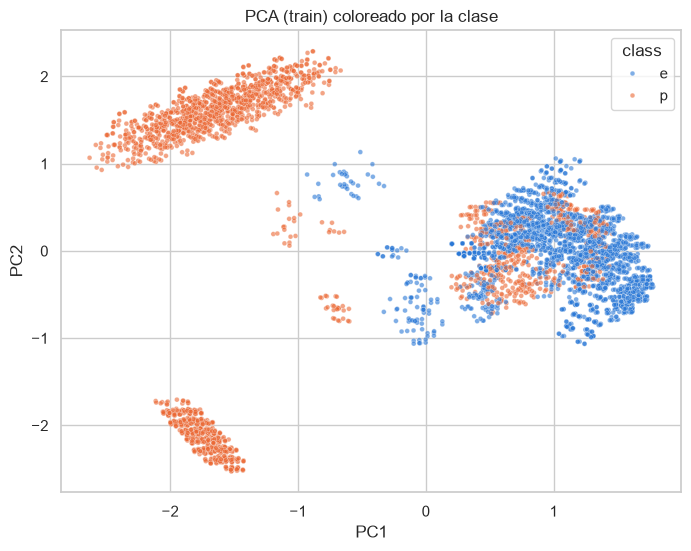

Varianza explicada por PC1 + PC2: 0.296


In [14]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca.fit(X_train)                      # se ajusta solo con train
X_train_2d = pca.transform(X_train)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_train_2d[:, 0], y=X_train_2d[:, 1], hue=y_train, palette=PALETA, s=12, alpha=0.6)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('PCA (train) coloreado por la clase')
plt.show()
print('Varianza explicada por PC1 + PC2:', round(pca.explained_variance_ratio_.sum(), 3))

Las dos primeras componentes retienen cerca del 30 % de la varianza y ya muestran zonas bastante diferenciadas, aunque con algo de solapamiento.

Antes de seguir, entrenamos un clasificador supervisado como **línea base** (así sabemos cuánta información hay realmente en los datos).

In [15]:
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
print('Accuracy en test:', rf.score(X_test, y_test))

Accuracy en test: 1.0


Es un conjunto sencillo y Random Forest es muy bueno. Veamos cuántas features tenemos:

In [16]:
X_train.shape

(5443, 115)

¿Muchas features, no? Vamos a reducirlas con PCA y ver cuántas componentes necesita Random Forest para mantener su precisión.

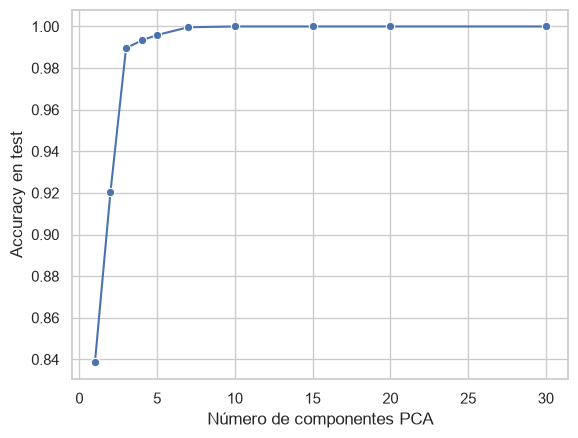

,n_componentes,accuracy
0,1,0.838493
1,2,0.920552
2,3,0.989556
3,4,0.993286
4,5,0.995897
5,7,0.999627
6,10,1.000000
7,15,1.000000
8,20,1.000000
9,30,1.000000


In [17]:
n_features = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30]
scores = []

for n in n_features:
    pca_n = PCA(n_components=n, random_state=RANDOM_STATE)
    train_n = pca_n.fit_transform(X_train)
    test_n = pca_n.transform(X_test)
    modelo = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE).fit(train_n, y_train)
    scores.append(modelo.score(test_n, y_test))

sns.lineplot(x=n_features, y=scores, marker='o')
plt.xlabel('Número de componentes PCA'); plt.ylabel('Accuracy en test')
plt.show()
pd.DataFrame({'n_componentes': n_features, 'accuracy': scores})

Con 3 componentes ya se ronda el 99 % de accuracy y con 10 se alcanza el 100 % en este test, usando menos del 10 % de las 115 columnas originales.

---
## t-SNE: reducción **no lineal** para visualizar

PCA es lineal. **t-SNE** intenta preservar la vecindad local y suele separar mejor los grupos visualmente. Es más caro, así que lo calculamos sobre una **muestra**.

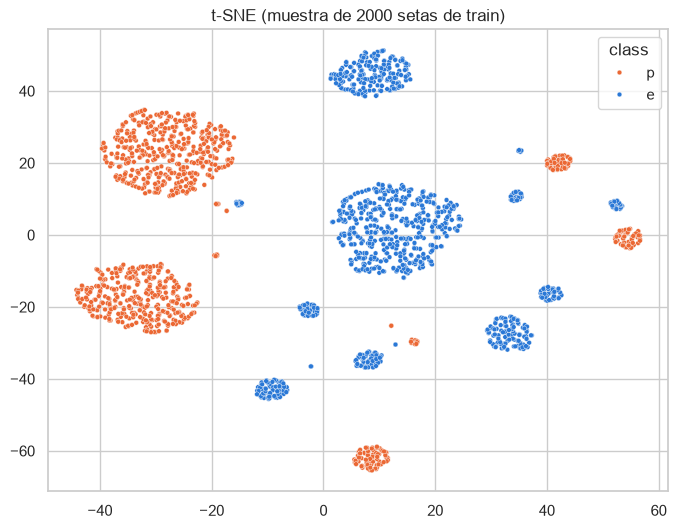

In [18]:
muestra = X_train.sample(n=2000, random_state=RANDOM_STATE)
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE)
emb = tsne.fit_transform(muestra)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_train.loc[muestra.index], palette=PALETA, s=12)
plt.title('t-SNE (muestra de 2000 setas de train)')
plt.show()

t-SNE separa muchos grupos pequeños y compactos, en general de una sola clase. Esto sugiere que hay más estructura que solo «comestible / venenosa». Las distancias entre grupos y sus tamaños en t-SNE no deben interpretarse literalmente.

## ¿Regresión, clasificación o clustering?

| Tipo | Aprendizaje | Qué hace | Ejemplo |
|---|---|---|---|
| Regresión | Supervisado | Predice un número | Estimar el peso de una seta (no está en este dataset) |
| Clasificación | Supervisado | Predice una categoría conocida | Random Forest: comestible o venenosa |
| Clustering | No supervisado | Agrupa por similitud, sin usar etiquetas | K-Means, Aglomerativo, GMM y DBSCAN |

En este taller `class` se usa para entrenar el Random Forest (clasificación). El clustering no la usa para formar los grupos; sirve después para validarlos.


---
## Clustering

El conjunto es sencillito, así que probemos clustering para ver qué información obtenemos **sin usar las etiquetas**. Trabajaremos sobre una representación reducida con PCA (10 componentes), que limpia ruido y acelera los algoritmos.

In [19]:
pca10 = PCA(n_components=10, random_state=RANDOM_STATE)
X_red = pca10.fit_transform(X)
print(X_red.shape, '| varianza retenida:', round(pca10.explained_variance_ratio_.sum(), 3))

(8124, 10) | varianza retenida: 0.645


### K-Means: ¿cuántos clusters? Codo + Silhouette

El **método del codo** mira la inercia (suma de distancias a los centroides). El **coeficiente de silhouette** mide cómo de bien separados están los clusters (cuanto más alto, mejor). Usamos ambos.

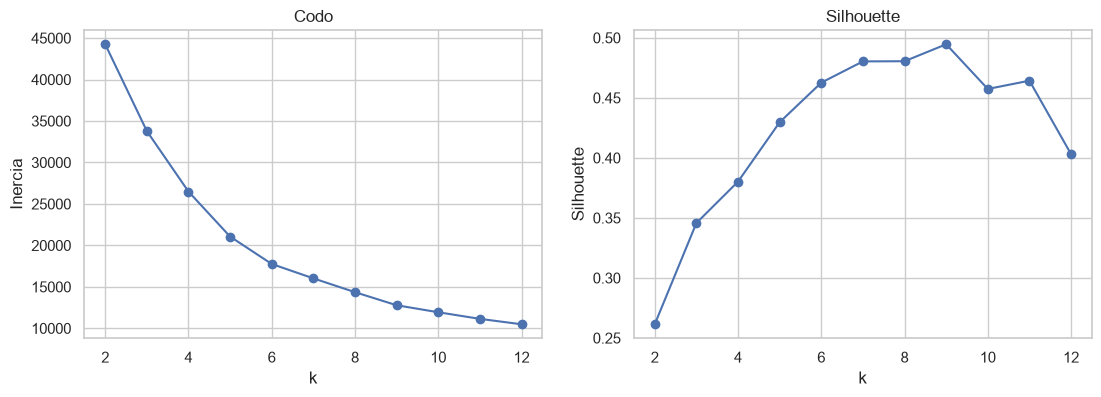

k con mayor silhouette: 9


In [20]:
k_values = range(2, 13)
inercias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_red)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_red, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_values, inercias, marker='o'); axes[0].set(title='Codo', xlabel='k', ylabel='Inercia')
axes[1].plot(k_values, silhouettes, marker='o'); axes[1].set(title='Silhouette', xlabel='k', ylabel='Silhouette')
plt.show()

k_silhouette = list(k_values)[int(np.argmax(silhouettes))]
print('k con mayor silhouette:', k_silhouette)

El codo no es nítido y la silhouette es máxima con **k = 9**, no con 2: sin etiqueta habríamos elegido más grupos. Usamos k = 2 a continuación porque queremos comparar con las dos clases conocidas (decisión basada en conocimiento del problema, no en las métricas internas).

### K-Means final y comparación con la etiqueta

Sabemos que hay dos clases (comestible / venenosa), así que probamos `k=2`. Con `catplot` vemos la distribución de la etiqueta real dentro de cada cluster.

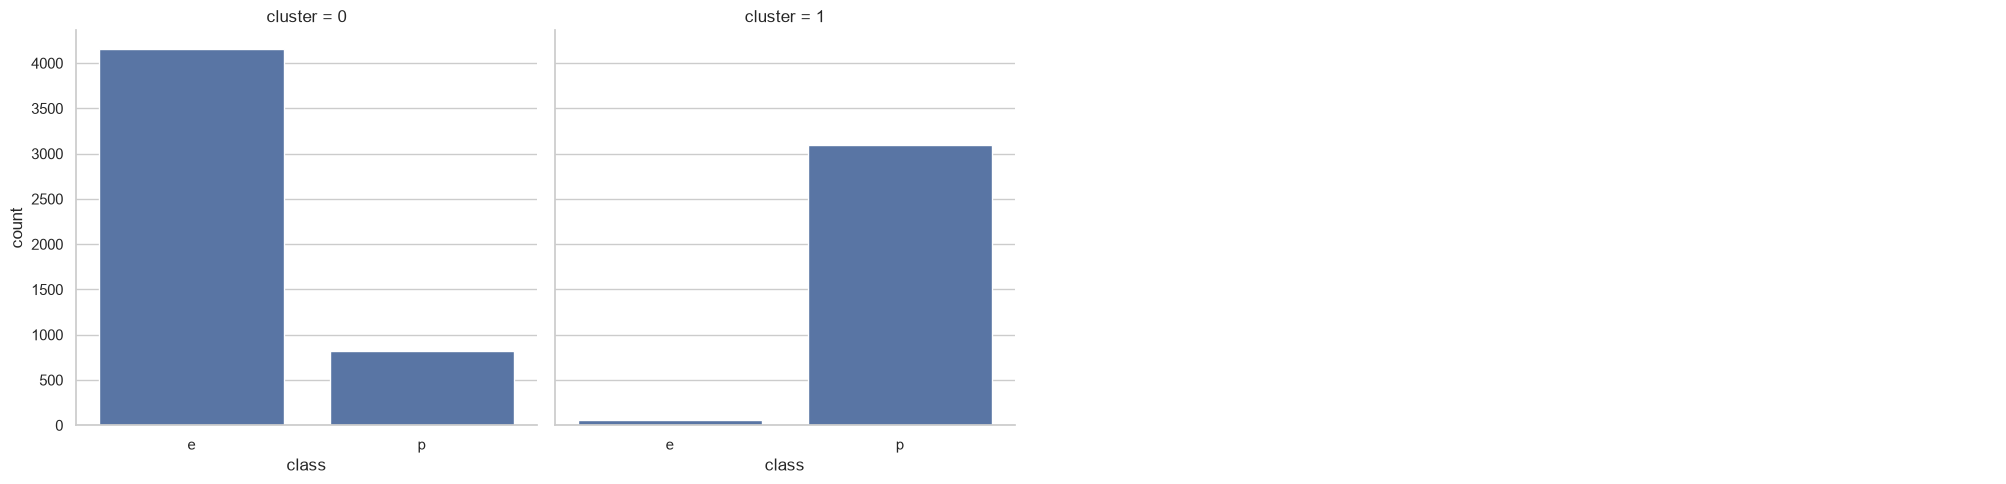

class,e,p
cluster,,
0,4153,816
1,55,3100


ARI: 0.617
NMI: 0.566


In [21]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_red)

res = pd.DataFrame({'cluster': kmeans.labels_, 'class': y.values})
sns.catplot(col='cluster', x='class', data=res, kind='count', col_wrap=4, order=['e', 'p'])
plt.show()

display(pd.crosstab(res['cluster'], res['class']))
print('ARI:', round(adjusted_rand_score(y_bin, kmeans.labels_), 3))
print('NMI:', round(normalized_mutual_info_score(y_bin, kmeans.labels_), 3))

In [22]:
# ¿Y si usamos el k que prefiere la silhouette? Miramos la pureza de cada cluster.
km_k = KMeans(n_clusters=k_silhouette, n_init=10, random_state=RANDOM_STATE).fit(X_red)
tabla = pd.crosstab(km_k.labels_, y.values, rownames=['cluster'], colnames=['class'])
display(tabla)
print('Pureza global:', round(tabla.max(axis=1).sum() / len(y), 3))
print('ARI:', round(adjusted_rand_score(y_bin, km_k.labels_), 3))

class,e,p
cluster,,
0,1728,0
1,7,1747
2,704,242
3,192,0
4,768,0
5,0,1296
6,260,219
7,549,124
8,0,288


Pureza global: 0.927
ARI: 0.266


Con más clusters el ARI baja porque penaliza dividir una misma clase en varios grupos. La **pureza** permite ver si esos grupos mezclan o no las clases, aunque tiende a subir al aumentar k.

> **ARI / NMI** comparan los clusters con la etiqueta real (0 = aleatorio, 1 = idéntico). Sin haber visto la etiqueta, K-Means recupera buena parte de la estructura comestible/venenosa, pero **no es perfecto**: ese es el reto real del no supervisado.

### Comparativa de algoritmos de clustering

Vamos a poner a competir **K-Means, Aglomerativo, GMM y DBSCAN** con varias métricas. Las tres primeras métricas son *internas* (no usan etiqueta); ARI sí la usa, para validar.

In [23]:
def evaluar(nombre, labels, X):
    labels = np.asarray(labels)
    validos = labels != -1                       # -1 = ruido (solo DBSCAN)
    n_clusters = len(np.unique(labels[validos]))
    fila = {'modelo': nombre, 'n_clusters': n_clusters, '% ruido': round(100 * (~validos).mean(), 2),
            'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan,
            'ARI': adjusted_rand_score(y_bin, labels)}
    if n_clusters > 1:                           # métricas internas sin contar el ruido
        fila['silhouette'] = silhouette_score(X[validos], labels[validos])
        fila['davies_bouldin'] = davies_bouldin_score(X[validos], labels[validos])
        fila['calinski_harabasz'] = calinski_harabasz_score(X[validos], labels[validos])
    return fila

modelos = {
    'KMeans (k=2)': kmeans.labels_,
    'Aglomerativo (k=2)': AgglomerativeClustering(n_clusters=2).fit_predict(X_red),
    'GMM (k=2)': GaussianMixture(n_components=2, random_state=RANDOM_STATE).fit_predict(X_red),
    'DBSCAN (eps=1.5)': DBSCAN(eps=1.5, min_samples=10).fit_predict(X_red),
}
comparativa = pd.DataFrame([evaluar(n, l, X_red) for n, l in modelos.items()])
comparativa.round(3)

,modelo,n_clusters,% ruido,silhouette,davies_bouldin,calinski_harabasz,ARI
0,KMeans (k=2),2,0.0,0.261,1.693,2564.691,0.617
1,Aglomerativo (k=2),2,0.0,0.259,1.696,2503.625,0.609
2,GMM (k=2),2,0.0,0.258,1.701,2500.017,0.599
3,DBSCAN (eps=1.5),6,0.0,0.358,1.071,2304.340,0.374


K-Means, Aglomerativo y GMM quedan muy parejos (ARI ≈ 0,60–0,62), con K-Means ligeramente por delante. DBSCAN encuentra más de dos grupos y su ARI es menor; sus métricas internas no son comparables directamente con las de los modelos de k = 2.

### Dendrograma (clustering jerárquico)

El clustering aglomerativo construye una jerarquía que podemos visualizar como **dendrograma**. La altura a la que se unen dos grupos indica cómo de distintos son. Lo calculamos sobre una muestra para que se lea bien.

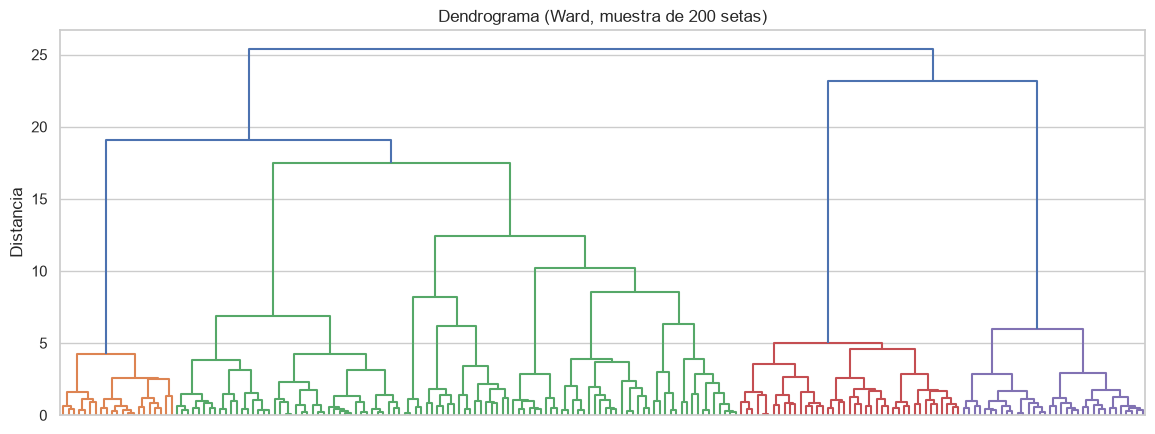

In [24]:
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(X_red), size=200, replace=False)
Z = linkage(X_red[idx], method='ward')

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True)
plt.title('Dendrograma (Ward, muestra de 200 setas)'); plt.ylabel('Distancia')
plt.show()

### DBSCAN: la **métrica de distancia importa**

DBSCAN agrupa por densidad. Pero con datos **categóricos** codificados en one-hot, la distancia euclídea no captura bien la similitud. Comparemos euclídea (sobre PCA) con la distancia de **Jaccard** (pensada para datos binarios).

,metrica,eps,n_clusters,% ruido,ARI
0,euclidean,0.80,51,0.54,0.088
1,euclidean,1.00,36,0.30,0.175
2,euclidean,1.20,21,0.18,0.175
3,euclidean,1.50,6,0.00,0.374
4,euclidean,2.00,4,0.00,0.080
5,jaccard,0.20,19,0.20,0.275
6,jaccard,0.30,14,0.20,0.262
7,jaccard,0.35,9,0.20,0.324
8,jaccard,0.40,5,0.10,0.443
9,jaccard,0.45,3,0.10,-0.001


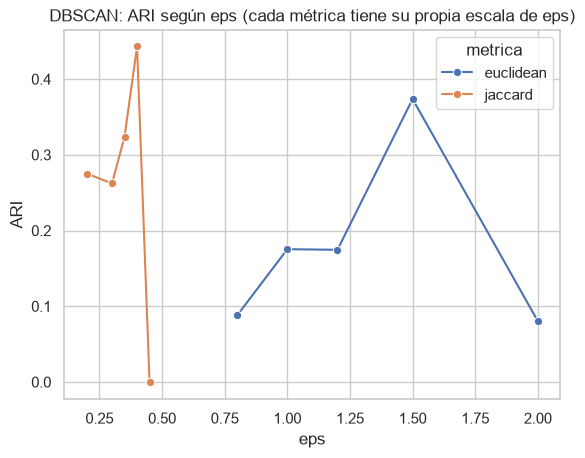

,metrica,eps,n_clusters,% ruido,ARI
3,euclidean,1.5,6,0.0,0.374
8,jaccard,0.4,5,0.1,0.443


In [25]:
X_bool = X.values.astype(bool)
pruebas = {'euclidean': (X_red, [0.8, 1.0, 1.2, 1.5, 2.0]),
           'jaccard':   (X_bool, [0.2, 0.3, 0.35, 0.4, 0.45])}

filas = []
for metrica, (datos, valores_eps) in pruebas.items():
    for eps in valores_eps:
        labels = DBSCAN(eps=eps, min_samples=10, metric=metrica).fit_predict(datos)
        filas.append({'metrica': metrica, 'eps': eps,
                      'n_clusters': len(set(labels)) - int(-1 in labels),
                      '% ruido': round(100 * np.mean(labels == -1), 2),
                      'ARI': adjusted_rand_score(y_bin, labels)})
res_db = pd.DataFrame(filas)
display(res_db.round(3))

sns.lineplot(data=res_db, x='eps', y='ARI', hue='metrica', marker='o')
plt.title('DBSCAN: ARI según eps (cada métrica tiene su propia escala de eps)')
plt.show()
res_db.loc[res_db.groupby('metrica')['ARI'].idxmax()].round(3)

> **Lección:** en estas pruebas, el mejor resultado con **Jaccard** (ARI ≈ 0,44) supera al mejor con **euclídea sobre PCA** (ARI ≈ 0,37). La mejora es real pero moderada, ambos quedan por debajo de K-Means con k = 2, y DBSCAN es muy sensible a `eps` (con Jaccard 0,45 el ARI cae a ≈ 0).
>
> El `eps` «mejor» se ha elegido mirando el ARI, es decir, usando la etiqueta. Vale como comparación didáctica; sin etiqueta habría que fijarlo con un gráfico k-distancia o métricas internas.

### Visualización final: clusters vs etiqueta real

Repetimos el scatter PCA, pero coloreando por el cluster de K-Means y por la etiqueta real, lado a lado.

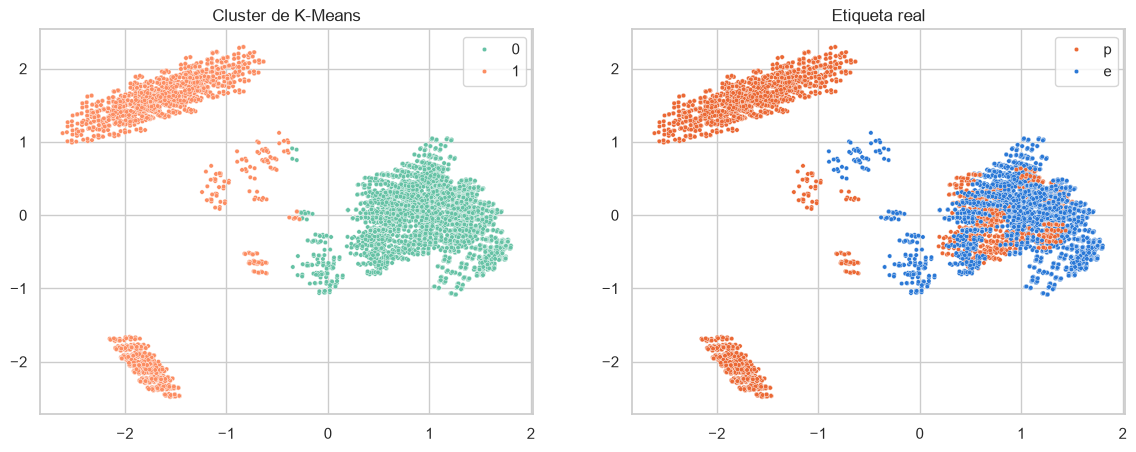

In [26]:
X_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=kmeans.labels_, palette='Set2', s=10, ax=axes[0])
axes[0].set_title('Cluster de K-Means')
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y.values, palette=PALETA, s=10, ax=axes[1])
axes[1].set_title('Etiqueta real')
plt.show()

El parecido es notable, pero no total: uno de los clusters es casi solo venenoso, mientras el otro mezcla las comestibles con varios cientos de venenosas. K-Means, **sin usar la etiqueta**, queda lejos del Random Forest supervisado. Un cluster «mayoritariamente comestible» **no** serviría para decidir si una seta se puede comer.

---
## Detección de anomalías (Isolation Forest)

Una tarea no supervisada distinta: encontrar las muestras **atípicas**. Isolation Forest aísla los puntos raros con pocos cortes aleatorios.

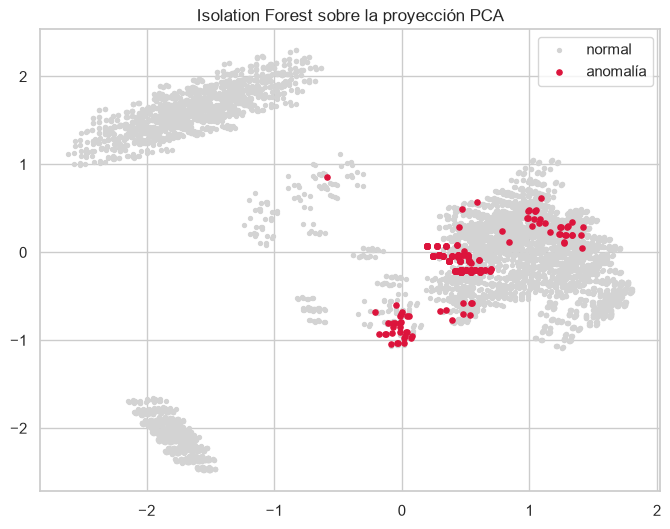

Anomalías: 244


class
e    209
p     35
Name: count, dtype: int64

In [27]:
iso = IsolationForest(contamination=0.03, random_state=RANDOM_STATE)
pred = iso.fit_predict(X_red)          # -1 = anomalía

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[pred == 1, 0], X_2d[pred == 1, 1], s=8, c='lightgrey', label='normal')
plt.scatter(X_2d[pred == -1, 0], X_2d[pred == -1, 1], s=14, c='crimson', label='anomalía')
plt.legend(); plt.title('Isolation Forest sobre la proyección PCA')
plt.show()

print('Anomalías:', (pred == -1).sum())
y[pred == -1].value_counts()

`contamination=0.03` fija de antemano la proporción de setas marcadas: es una decisión nuestra, no un descubrimiento del modelo. «Atípica» significa poco frecuente en sus características, no venenosa.

---
## Para ir más allá (opcional)

- **UMAP** (`pip install umap-learn`): alternativa a t-SNE, más rápida y suele preservar mejor la estructura global.
- **HDBSCAN** (`pip install hdbscan`): DBSCAN jerárquico que no necesita fijar `eps`.
- **Reglas de asociación** (`mlxtend`, Apriori/FP-Growth): muy naturales aquí por ser datos categóricos.

## Conclusiones

- Los datos tienen muchísima información sobre la clase: Random Forest alcanza el 100 % en test, y mantiene ese resultado con 10 componentes PCA.
- PCA y t-SNE permiten *ver* en 2D un dataset de 115 columnas tras el One-Hot Encoding.
- K-Means, Aglomerativo y GMM con k = 2 recuperan parte de la estructura comestible/venenosa (ARI ≈ 0,60–0,62) **sin usar la etiqueta**.
- Las métricas internas prefieren más grupos (k = 9 por silhouette): los clusters naturales no tienen por qué coincidir con las clases.
- En DBSCAN la distancia y `eps` importan: Jaccard mejoró a la euclídea de forma moderada.
- Isolation Forest localiza setas atípicas, según la proporción que fijemos.